![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Downscaling Soil Moisture: Six Methods Compared

SMAP measures soil moisture accurately, but at 9 km (from 36 km footprints); farms, catchments and
irrigation decisions need 1 km or finer. Downscaling borrows the spatial detail of a finer variable
that responds to soil moisture: land surface temperature, an optical index, radar backscatter, soil
texture or terrain. Dozens of methods exist, and published comparisons rarely use the same data. This
notebook downscales SMAP L3 Enhanced from 9 km to the 1 km EASE grid over central Iowa for the
growing seasons of 2019 to 2021 with six families of methods on identical inputs, and tests them in
the same way: against the operational SMAP/Sentinel-1 1 km product, against two in situ stations,
for mass conservation, and, most importantly, against the trivial baseline of copying each 9 km value
into its 81 sub-cells.

## Overview

### Two rules for any downscaling method

1. **Mass conservation**: the 1 km values inside a 9 km cell should average to the 9 km value. Then the
   method only adds spatial pattern and keeps the level and accuracy of the coarse product.
2. **Beat the baseline**: a 1 km map is only useful if it is closer to the truth than the coarse
   value copied into every sub-cell. Correlating a downscaled map with stations mostly rewards the
   coarse signal it inherits; what counts is the part it adds.

### The six methods

| # | Method | Fine-scale information | Idea |
|---|---|---|---|
| 0 | Baseline | none | copy each 9 km value to its 81 cells of 1 km |
| 1 | Regression + smooth interpolation | soil texture, organic carbon, elevation, slope | pooled linear regression of coarse anomalies on aggregated static covariates, applied at 1 km as a zero-mean pattern, added to a mass-preserving (pycnophylactic) smooth surface through the 9 km values |
| 2a | DisPATCh | MODIS LST and NDVI | soil evaporative efficiency (SEE) from the LST-NDVI space; `SM = SM_c + SMp (SEE - SEE_c)` (Merlin et al. 2012) |
| 2b | OPTRAM | MODIS NBAR SWIR and NDVI | the same linear scheme with the OPTRAM moisture index (Sadeghi et al. 2017) instead of SEE |
| 3 | Active-passive (SAR) | Sentinel-1 VV at 50 m | `SM = SM_c + beta (sigma - sigma_c)` (Das et al. 2014), aggregated to 1 km |
| 4 | Machine learning + residual | NDVI, rain, texture, terrain, crops, season | XGBoost trained on coarse cells, applied at 1 km, coarse residual added back |
| 5 | Deep learning (U-Net) | the same covariates | a residual U-Net that learns the 1 km correction from SPL2SMAP_S 1 km targets |
| 6 | Fusion | methods 1 to 4 | weighted mean with weights from each method's error in the training years |

### How the methods are judged

The truth at 1 km is unknown. Two imperfect references are used: the SMAP/Sentinel-1 product
SPL2SMAP_S at 1 km (an independent algorithm, but sharing SMAP and Sentinel-1 with methods 3 and 5) and
the 5 cm sensors of two stations (true points, but not representative of 1 km). For every method:

- **Within-cell skill**: the correlation between the pattern a method adds (`method - baseline`) and the
  pattern of the reference (`reference - baseline`), over all cells and days. Zero means no useful
  sub-cell information.
- **Gain over the baseline**: `1 - ubRMSD(method) / ubRMSD(baseline)` against the reference. Positive
  means better than copying the coarse value.
- **Mass conservation error**: the mean absolute difference between the 9 km block mean of the 1 km
  map and the 9 km value.
- **Availability**: the share of cells and days with a value (thermal and SAR methods are gappy).

U-Net and fusion learn from SPL2SMAP_S in 2019 and 2020, so all comparisons with SPL2SMAP_S use 2021 only.

## Downscaling with GeoLattice

| Function | Purpose |
|---|---|
| `sd.downscaling_stack()` | cached daily inputs on nested 9 km and 1 km EASE cells |
| `sm.nested_upsample`, `sm.block_mean` | move between nested grids exactly |
| `sm.pycnophylactic` | mass-preserving smooth interpolation of coarse residuals (method 1) |
| `sm.ts_vi_edges`, `sm.soil_evaporative_efficiency`, `sm.dispatch` | DisPATCh (method 2a) |
| `sm.str_transform`, `sm.optram_edges`, `sm.optram` | OPTRAM (method 2b) |
| `sm.short_term_change_detection`, `sm.regrid` | SAR disaggregation (method 3) |
| `sm.spatial_blocks`, `sm.ml_downscale`, `sm.explain_downscaling` | machine learning (method 4) |
| `sm.unet_downscale`, `sm.predict_unet` | U-Net (method 5) |
| `sm.merge_products` | fusion (method 6) |
| `sm.validation_metrics` | metrics |

### Learning objectives

1. Build a consistent set of fine-scale predictors on a grid nested in the coarse product.
2. Implement six families of downscaling methods on identical inputs.
3. Measure within-cell skill, gain over the coarse baseline, mass conservation and availability.
4. Decide which method suits which purpose (daily maps, field patterns, clear-sky only, all weather).

### Data

| Dataset | Content |
|---|---|
| SMAP L3 Enhanced (SPL3SMP_E v006) | 9 km AM-first soil moisture, all successful retrievals, April to October 2019 to 2021 |
| MODIS MOD11A1, MOD13A1, MCD43A4 (Planetary Computer) | daily 1 km LST day and night, 16-day NDVI (interpolated daily), daily NBAR red, NIR and SWIR |
| Sentinel-1 RTC (notebook 11) | VV at 50 m, relative orbit 165, every 12 days |
| gridMET | daily precipitation, summed over the 3 and 10 days before each date |
| SoilGrids 2.0, Copernicus DEM, USDA CDL | sand, clay, organic carbon; elevation and slope; corn and soybean fractions per year |
| SPL2SMAP_S v003 (notebook 14) | 1 km reference on Sentinel-1 days |
| USCRN Des Moines 17 E, SCAN Ames | in situ 5 cm |

### Contents

- Setup
- The nested grids and the inputs
- Method 0: the baseline
- Method 1: regression with smooth interpolation
- Method 2: DisPATCh and OPTRAM
- Method 3: SAR active-passive disaggregation
- Method 4: machine learning with residual correction
- Method 5: a residual U-Net
- Method 6: fusion
- Maps on one day
- The comparison
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

import time  # timing
from pyproj import Transformer  # station positions
F = 9  # 1 km cells per 9 km cell along each axis
ds = sd.downscaling_stack()  # cached inputs (April to October 2019 to 2021)
coarse = ds.smap_9km.rename({"y9": "y", "x9": "x"}).rio.write_crs("EPSG:6933")  # SMAP 9 km cube
tmpl = ds.sand  # the 1 km grid
days = pd.DatetimeIndex(ds.time.values)  # all days of the three seasons
print(f"{len(days)} days; coarse grid {coarse.sizes['y']} x {coarse.sizes['x']} cells of 9 km; fine grid {tmpl.sizes['y']} x {tmpl.sizes['x']} cells of 1 km")  # sizes
print("fine coordinates nested exactly:", bool(np.allclose(sm.nested_upsample(coarse.isel(time=0), F).x, tmpl.x)))  # check
products, timing = {}, {}  # results of each method and run times

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


642 days; coarse grid 9 x 8 cells of 9 km; fine grid 81 x 72 cells of 1 km
fine coordinates nested exactly: True


## The nested grids and the inputs

The 1 km EASE-Grid 2.0 nests exactly in the 9 km grid (9 x 9 cells), so block means and copies need no
resampling.

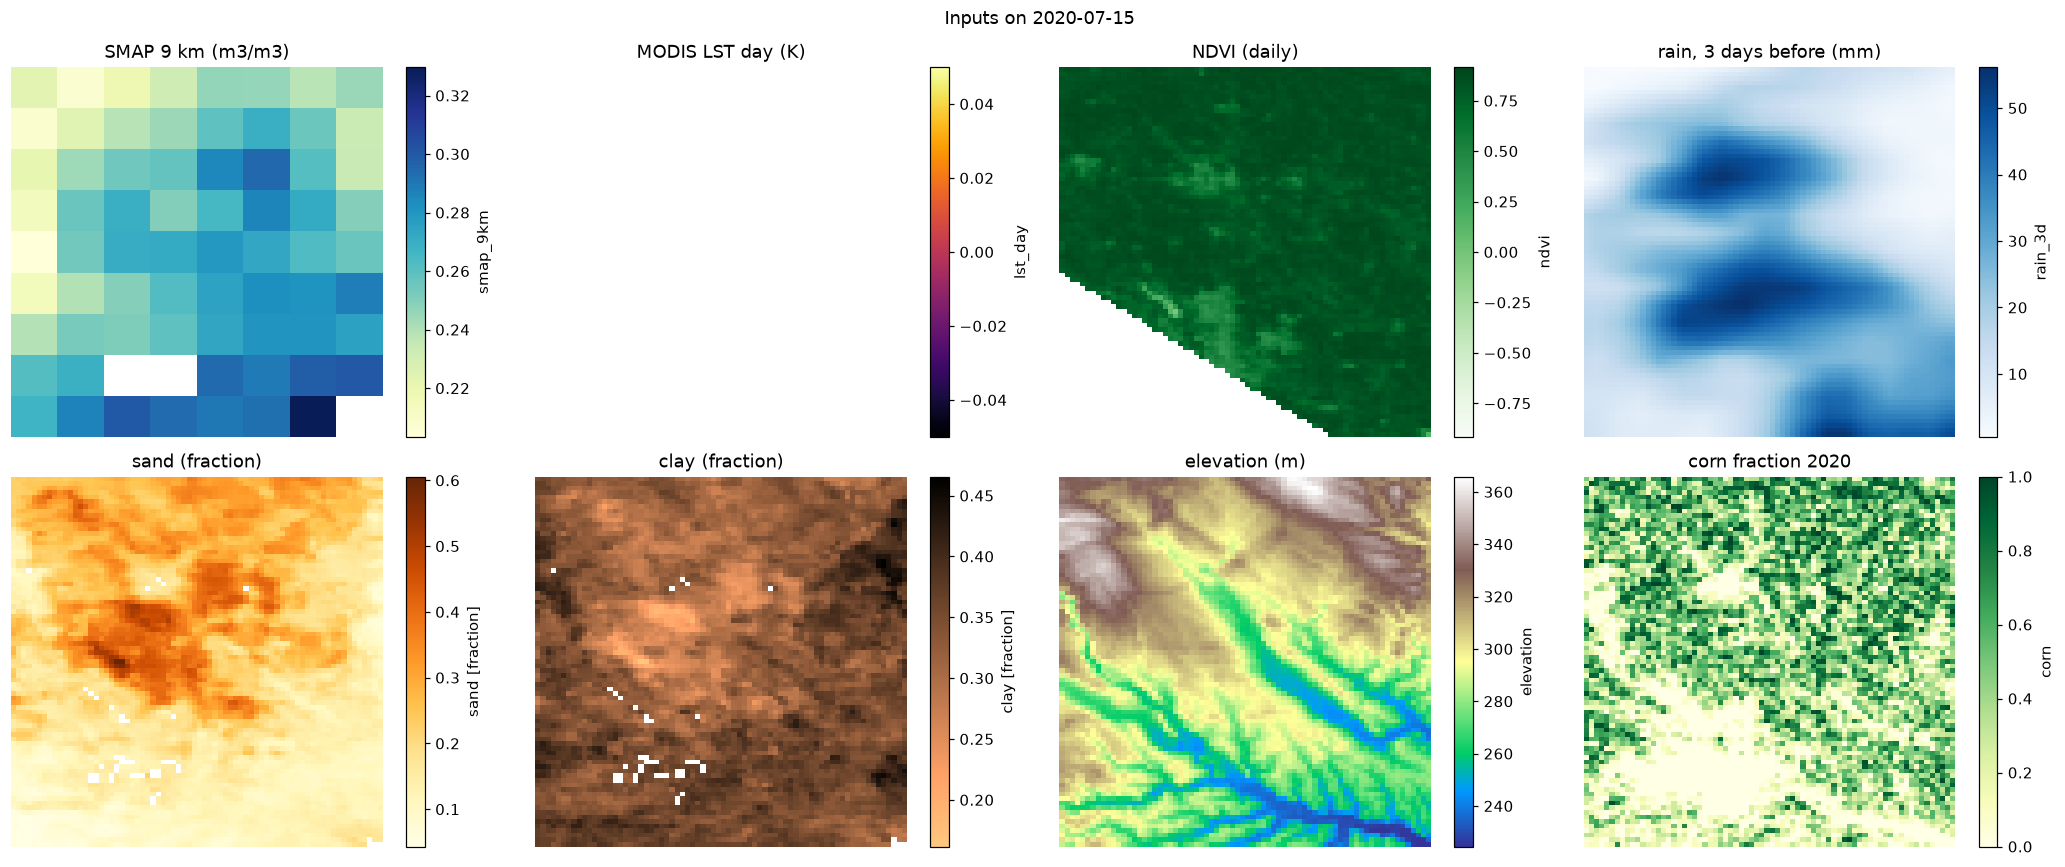

SMAP 9 km cell-days with a value: 0.54


,lst_day,lst_night,ndvi,swir22,rain_3d
share of cell-days,0.42,0.49,0.82,0.83,1.0


In [2]:
fig, ax = plt.subplots(2, 4, figsize=(19, 8))  # eight inputs
d0 = "2020-07-15"  # example day
panels = [(coarse.sel(time=d0), "SMAP 9 km (m3/m3)", "YlGnBu"), (ds.lst_day.sel(time=d0), "MODIS LST day (K)", "inferno"),
          (ds.ndvi.sel(time=d0), "NDVI (daily)", "Greens"), (ds.rain_3d.sel(time=d0), "rain, 3 days before (mm)", "Blues"),
          (ds.sand, "sand (fraction)", "YlOrBr"), (ds.clay, "clay (fraction)", "copper_r"), (ds.elevation, "elevation (m)", "terrain"),
          (ds.corn.sel(time=d0), "corn fraction 2020", "YlGn")]  # inputs
for a, (da, title, cmap) in zip(ax.ravel(), panels):  # each panel
    da.plot(ax=a, cmap=cmap, add_colorbar=True); a.set_title(title); a.axis("off")  # map
plt.suptitle(f"Inputs on {d0}"); plt.tight_layout(); plt.show()  # draw
avail = pd.Series({v: float(ds[v].notnull().mean()) for v in ("lst_day", "lst_night", "ndvi", "swir22", "rain_3d")})  # share of cell-days with data
print("SMAP 9 km cell-days with a value:", round(float(coarse.notnull().mean()), 2)); display(avail.round(2).to_frame("share of cell-days").T)  # availability

## Method 0: the baseline

In [3]:
base = sm.nested_upsample(coarse, F)  # copy every 9 km value to its 81 cells of 1 km
products["0 baseline"] = base  # store
print(base.sizes)  # dimensions

Frozen({'time': 642, 'y': 81, 'x': 72})


## Method 1: regression with smooth interpolation

The daily mean is removed from the coarse values; the anomalies are regressed (pooled over all days) on
the static covariates averaged to 9 km; the regression is applied at 1 km as a pattern with zero mean in
every 9 km cell. It is added to a smooth surface through the coarse values made with the pycnophylactic
interpolation (Tobler 1979), which removes the blocky cell edges while keeping every block mean, a simple
stand-in for area-to-point kriging.

In [4]:
t0 = time.time()  # start
from sklearn.linear_model import LinearRegression  # pooled regression
STATIC = ["sand", "clay", "soc", "elevation", "slope"]  # static covariates
Xf = xr.Dataset({v: ds[v] for v in STATIC})  # at 1 km
Xc = xr.Dataset({v: sm.block_mean(ds[v].rio.write_crs("EPSG:6933"), F) for v in STATIC})  # at 9 km
anom = coarse - coarse.mean(("y", "x"))  # daily spatial anomalies at 9 km
tab = anom.to_dataframe(name="a").reset_index()[["time", "y", "x", "a"]].merge(Xc.to_dataframe().reset_index()[["y", "x"] + STATIC], on=["y", "x"]).dropna()  # samples
mu, sdv = tab[STATIC].mean(), tab[STATIC].std()  # standardisation
reg = LinearRegression().fit((tab[STATIC] - mu) / sdv, tab["a"])  # pooled fit
print("standardised coefficients (m3/m3 per std):", dict(zip(STATIC, np.round(reg.coef_, 4))), "| R2", round(reg.score((tab[STATIC] - mu) / sdv, tab["a"]), 2))  # fit
pattern = sum(((Xf[v] - mu[v]) / sdv[v]) * c for v, c in zip(STATIC, reg.coef_))  # static pattern at 1 km
pattern = pattern - sm.nested_upsample(sm.block_mean(pattern.rio.write_crs("EPSG:6933"), F), F).values  # zero block mean: adds pattern, not level
smooth = sm.pycnophylactic(coarse, F, iterations=30)  # smooth surface through the 9 km cells, block means kept
m1 = smooth + pattern.values  # smooth coarse field plus the static pattern
products["1 regression + smooth"] = m1.clip(0.02, 0.6)  # store
timing["1 regression + smooth"] = time.time() - t0  # run time

standardised coefficients (m3/m3 per std): {'sand': np.float32(-0.0096), 'clay': np.float32(-0.0026), 'soc': np.float32(-0.0011), 'elevation': np.float32(-0.0049), 'slope': np.float32(0.0005)} | R2 0.2


The static covariates explain about 20 % of the spatial anomalies between the 72 cells of 9 km; sand
has the largest (negative) effect, as sandier soils drain and dry faster, followed by elevation.

Because the pattern has a zero mean in every 9 km block and the smooth surface keeps the block means, method
1 conserves mass by construction. Its sub-cell pattern is the same on every day: a smooth gradient between
neighbouring cells plus the texture and terrain pattern of the regression.

## Method 2: DisPATCh and OPTRAM

DisPATCh needs a clear-sky day: the LST-NDVI edges define the soil temperature end-members and the soil
evaporative efficiency (SEE) of each 1 km cell; SMAP is then redistributed with
`SM = SM_c + SMp (SEE - SEE_c)`, where the soil moisture parameter `SMp = SM_c / SEE_c` is computed per 9 km
cell. A domain of 81 x 72 cells is small for drawing edges, so they are fitted on the clear days within
eight days of each date, and `SMp` is capped at 0.45 m3 m-3; both settings were chosen on 2019 and 2020
only (a first version with daily edges and a cap of 0.6 had more than twice the error). OPTRAM uses the
SWIR transformed reflectance instead of temperature, with edges fitted once over the three seasons on
vegetated pixels (NDVI 0.2 to 0.85).

In [5]:
t0 = time.time()  # start
dis = xr.full_like(base, np.nan)  # DisPATCh result
used = 0  # clear days processed
WIN, SMP_MAX = 8, 0.45  # edges from the clear days within +-8 days; cap of the soil moisture parameter (chosen on 2019 and 2020)
for i, d in enumerate(days):  # each day
    lst, nd = ds.lst_day.isel(time=i), ds.ndvi.isel(time=i)  # inputs of the day
    c = coarse.isel(time=i)  # SMAP of the day
    if float(lst.notnull().mean()) < 0.5 or float(c.notnull().mean()) < 0.5:  # need a mostly clear day and SMAP
        continue
    sl = slice(max(0, i - WIN), i + WIN + 1)  # neighbouring days
    try:
        e = sm.ts_vi_edges(ds.lst_day.isel(time=sl), ds.ndvi.isel(time=sl), ndvi_bins=20, quantile=0.02, ndvi_range=(0.15, 0.9))  # pooled edges
    except ValueError:  # too few populated NDVI bins
        continue
    see = sm.soil_evaporative_efficiency(lst, nd, edges=e).rio.write_crs("EPSG:6933")  # SEE at 1 km
    smp = (c / sm.block_mean(see, F).values).clip(0.1, SMP_MAX).rio.write_crs("EPSG:6933")  # soil moisture parameter per 9 km cell
    dis[i] = sm.dispatch(c, see, sm_p=smp).values  # DisPATCh
    used += 1  # count
products["2a DisPATCh (LST)"] = dis  # store
timing["2a DisPATCh (LST)"] = time.time() - t0  # run time
print(f"DisPATCh run on {used} of {len(days)} days (clear sky and SMAP)")  # coverage
t0 = time.time()  # start
ndvi_nbar = (ds.nir - ds.red) / (ds.nir + ds.red)  # NDVI from the same NBAR reflectance
strf = sm.str_transform(ds.swir22)  # SWIR transformed reflectance
veg = ndvi_nbar > 0.1  # leave water and bare urban surfaces out of the edge fit
oe = sm.optram_edges(strf.where(veg), ndvi_nbar.where(veg), ndvi_bins=30, quantile=0.02, ndvi_range=(0.2, 0.85))  # edges over all days
W = sm.optram(strf, ndvi_nbar, oe).rio.write_crs("EPSG:6933")  # OPTRAM moisture index (0 dry, 1 wet)
print("OPTRAM edges:", {k: round(v, 2) for k, v in oe.items()})  # parameters
opt = xr.full_like(base, np.nan)  # OPTRAM downscaling
for i in range(len(days)):  # each day
    w, c = W.isel(time=i), coarse.isel(time=i)  # inputs
    if float(w.notnull().mean()) < 0.5 or float(c.notnull().mean()) < 0.5:  # need data
        continue
    smp = (c / sm.block_mean(w, F).values).clip(0.1, SMP_MAX).rio.write_crs("EPSG:6933")  # soil moisture parameter per cell
    opt[i] = sm.dispatch(c, w.clip(0.01, 0.99), sm_p=smp).values  # same linear scheme with W instead of SEE
products["2b OPTRAM"] = opt  # store
timing["2b OPTRAM"] = time.time() - t0  # run time

DisPATCh run on 179 of 642 days (clear sky and SMAP)


OPTRAM edges: {'i_d': -0.69, 's_d': 3.91, 'i_w': 4.69, 's_w': 1.12}


DisPATCh runs on 179 of the 642 days: the rest are cloudy or lack SMAP. The OPTRAM edges now have the
expected shape, the wet edge above the dry edge at every NDVI.

## Method 3: SAR active-passive disaggregation

Sentinel-1 VV at 50 m distributes SMAP inside each 9 km cell (notebook 12), then the 50 m result is
averaged to 1 km. It exists only on Sentinel-1 days.

In [6]:
t0 = time.time()  # start
s1 = sd.s1_cube()  # notebook 11 cube (UTM, 50 m)
s1 = s1.sel(time=s1.time.dt.month.isin(list(sd.DS_MONTHS)))  # same months
sday = pd.DatetimeIndex(s1.time.values).normalize()  # Sentinel-1 days
cs = coarse.reindex(time=sday, method="nearest", tolerance=pd.Timedelta(days=1)).assign_coords(time=s1.time.values).rio.write_crs("EPSG:6933")  # SMAP on S1 days
apd = sm.short_term_change_detection(s1.vv, cs, min_obs=8)  # 50 m disaggregation
a1 = sm.regrid(apd.sm, tmpl, method="average")  # to 1 km
a1 = a1.assign_coords(time=sday).groupby("time").mean().reindex(time=days)  # daily calendar
products["3 SAR active-passive"] = a1  # store
timing["3 SAR active-passive"] = time.time() - t0  # run time
print(f"{int(a1.notnull().any(('y', 'x')).sum())} Sentinel-1 days; median beta {float(apd.beta.median()):.4f} m3/m3 per dB")  # summary

40 Sentinel-1 days; median beta 0.0305 m3/m3 per dB


## Method 4: machine learning with residual correction

XGBoost learns SMAP 9 km from the covariates averaged to 9 km (cells and days stacked), with spatial
block cross-validation, then predicts at 1 km; the coarse residual of each cell is added back. Only
gap-free covariates are used, so the result is daily and complete.

,fold,n_test,r2,rmse
0,0,8230,0.793,0.028
1,1,4880,0.793,0.028
2,2,5337,0.786,0.027
3,3,6247,0.790,0.027


training samples: 24,694


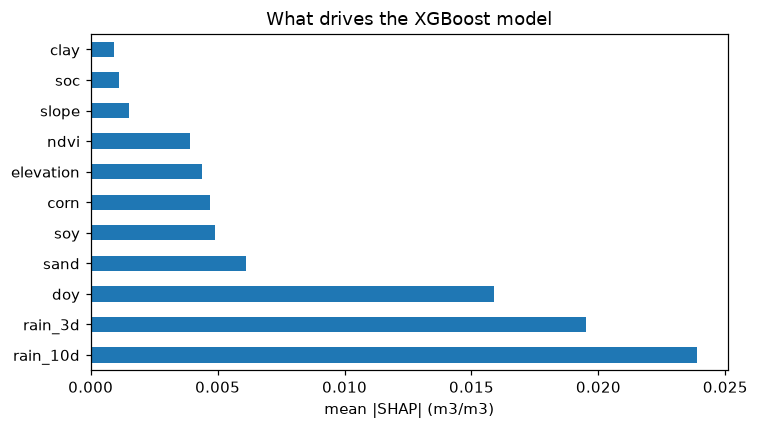

In [7]:
t0 = time.time()  # start
FEAT = ["ndvi", "rain_3d", "rain_10d", "sand", "clay", "soc", "elevation", "slope", "corn", "soy"]  # gap-free covariates
pred = xr.Dataset({v: ds[v].broadcast_like(ds.ndvi) for v in FEAT})  # time, y, x
pred["ndvi"] = pred.ndvi.fillna(pred.ndvi.mean("time")).fillna(float(pred.ndvi.mean()))  # remaining NDVI gaps: the pixel's season mean
pred["doy"] = xr.DataArray(days.dayofyear.values.astype("float32"), coords={"time": days}, dims="time").broadcast_like(ds.ndvi)  # season
pred = pred.transpose("time", "y", "x").rio.write_crs("EPSG:6933")  # order for regridding
folds = sm.spatial_blocks(coarse.isel(time=0, drop=True), block_size_m=27_000, n_folds=4)  # 3 x 3 cell blocks
fine4, rep = sm.ml_downscale(coarse, pred, model="xgboost", residual=True, folds=folds,
                             params={"n_estimators": 300, "max_depth": 4, "learning_rate": 0.05})  # train and predict
products["4 XGBoost + residual"] = fine4.where(coarse.reindex_like(fine4, method="nearest").notnull())  # same days as SMAP
timing["4 XGBoost + residual"] = time.time() - t0  # run time
display(rep["cv"].round(3)); print(f"training samples: {rep['n_train']:,}")  # spatial cross-validation of the coarse model
ex = sm.explain_downscaling(rep["model"], pred.isel(time=slice(0, None, 10)), sample=4000)  # SHAP on every tenth day
ex["importance"].round(4).plot.barh(figsize=(7, 4)); plt.xlabel("mean |SHAP| (m3/m3)"); plt.title("What drives the XGBoost model"); plt.tight_layout(); plt.show()  # importance

The coarse-scale model is good: R2 of about 0.79 in every spatial fold. But the SHAP values show why
that says little about the 1 km pattern: rain over the previous 10 and 3 days and the day of year
dominate, and those vary in time much more than between the 1 km cells of one 9 km cell. Sand, the crop
fractions and elevation, which carry the sub-cell pattern, contribute far less.

## Method 5: a residual U-Net

The network sees the SMAP field interpolated to 1 km and the covariates, and learns the correction to the
SPL2SMAP_S 1 km map on the Sentinel-1 days of 2019 and 2020; it is then applied to every day of 2021.

30 training days; final train RMSE 0.056, validation RMSE 0.048 m3/m3


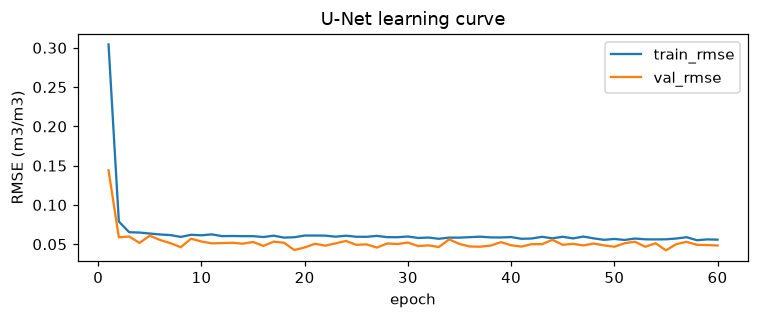

In [8]:
t0 = time.time()  # start
spl = sd.spl2smap_s().sm_1km.rename({"y_1km": "y", "x_1km": "x"})  # SPL2SMAP_S 1 km
spl = spl.assign_coords(time=pd.DatetimeIndex(spl.time.values).normalize()).groupby("time").mean()  # one map per day
spl = spl.reindex(x=tmpl.x, y=tmpl.y, method="nearest", tolerance=50).reindex(time=days)  # on the nested 1 km grid
bil = sm.nested_upsample(coarse, F, method="bilinear")  # SMAP interpolated between cell centres
cov = ["ndvi", "sand", "clay", "elevation", "rain_3d"]  # covariates of the network
pairs = xr.Dataset({"coarse": bil, **{v: ds[v].broadcast_like(ds.ndvi) for v in cov}, "target": spl}).transpose("time", "y", "x")  # inputs and target
train_days = [d for d in days if d.year < 2021 and float(spl.sel(time=d).notnull().mean()) > 0.2 and float(bil.sel(time=d).notnull().mean()) > 0.5]  # training days
INP = ["coarse"] + cov  # network inputs
fill = lambda d: d.assign({v: d[v].fillna(float(d[v].mean())) for v in INP})  # fill input gaps only, never the target
net, hist = sm.unet_downscale(fill(pairs.sel(time=train_days)), epochs=60, patch=48, batch=16, val_fraction=0.2)  # train
d21 = [d for d in days if d.year == 2021 and float(bil.sel(time=d).notnull().mean()) > 0.5]  # 2021 days with SMAP
inp = fill(pairs.sel(time=d21))  # 2021 inputs
u = sm.predict_unet(net, inp.coarse, inp)  # prediction
u = u.where(coarse.sel(time=d21).reindex_like(u, method="nearest").notnull())  # only where SMAP exists
products["5 U-Net"] = u.reindex(time=days)  # store (2021 only)
timing["5 U-Net"] = time.time() - t0  # run time
print(f"{len(train_days)} training days; final train RMSE {hist.train_rmse.iloc[-1]:.3f}, validation RMSE {hist.val_rmse.iloc[-1]:.3f} m3/m3")  # learning
hist.set_index("epoch").plot(figsize=(7, 3)); plt.ylabel("RMSE (m3/m3)"); plt.title("U-Net learning curve"); plt.tight_layout(); plt.show()  # curve

The network learns quickly from 30 training days. The checkerboard pattern it leaves at the edges of the
domain comes from the transposed convolutions of the decoder, a known U-Net artifact on small grids.

## Method 6: fusion

Each of methods 1 to 4 gets a weight from its unbiased error against SPL2SMAP_S in 2019 and 2020
(`w = 1 / ubRMSD^2`, normalised); where a method has no value (clouds, no Sentinel-1 pass) the weights of the
others are renormalised.

In [9]:
t0 = time.time()  # start
def ubrmsd(a, b):  # unbiased RMS difference over all cells and days
    d = (a - b).values.ravel(); d = d[np.isfinite(d)]  # differences
    return float(np.sqrt(np.mean((d - d.mean()) ** 2))) if d.size > 50 else np.nan  # value
members = ["1 regression + smooth", "2a DisPATCh (LST)", "2b OPTRAM", "3 SAR active-passive", "4 XGBoost + residual"]  # fusion members
train = days.year < 2021  # training years
err = {k: ubrmsd(products[k].sel(time=train), spl.sel(time=train)) for k in members}  # errors in 2019 and 2020
print({k: round(v, 4) for k, v in err.items()})  # errors
fused = sm.merge_products({k: products[k] for k in members}, errors=err, rescale=False)  # weighted mean, no rescaling
products["6 fusion"] = fused.sm  # store
timing["6 fusion"] = time.time() - t0  # run time

{'1 regression + smooth': 0.0578, '2a DisPATCh (LST)': 0.0787, '2b OPTRAM': 0.0726, '3 SAR active-passive': 0.0614, '4 XGBoost + residual': 0.0586}


## Maps on one day

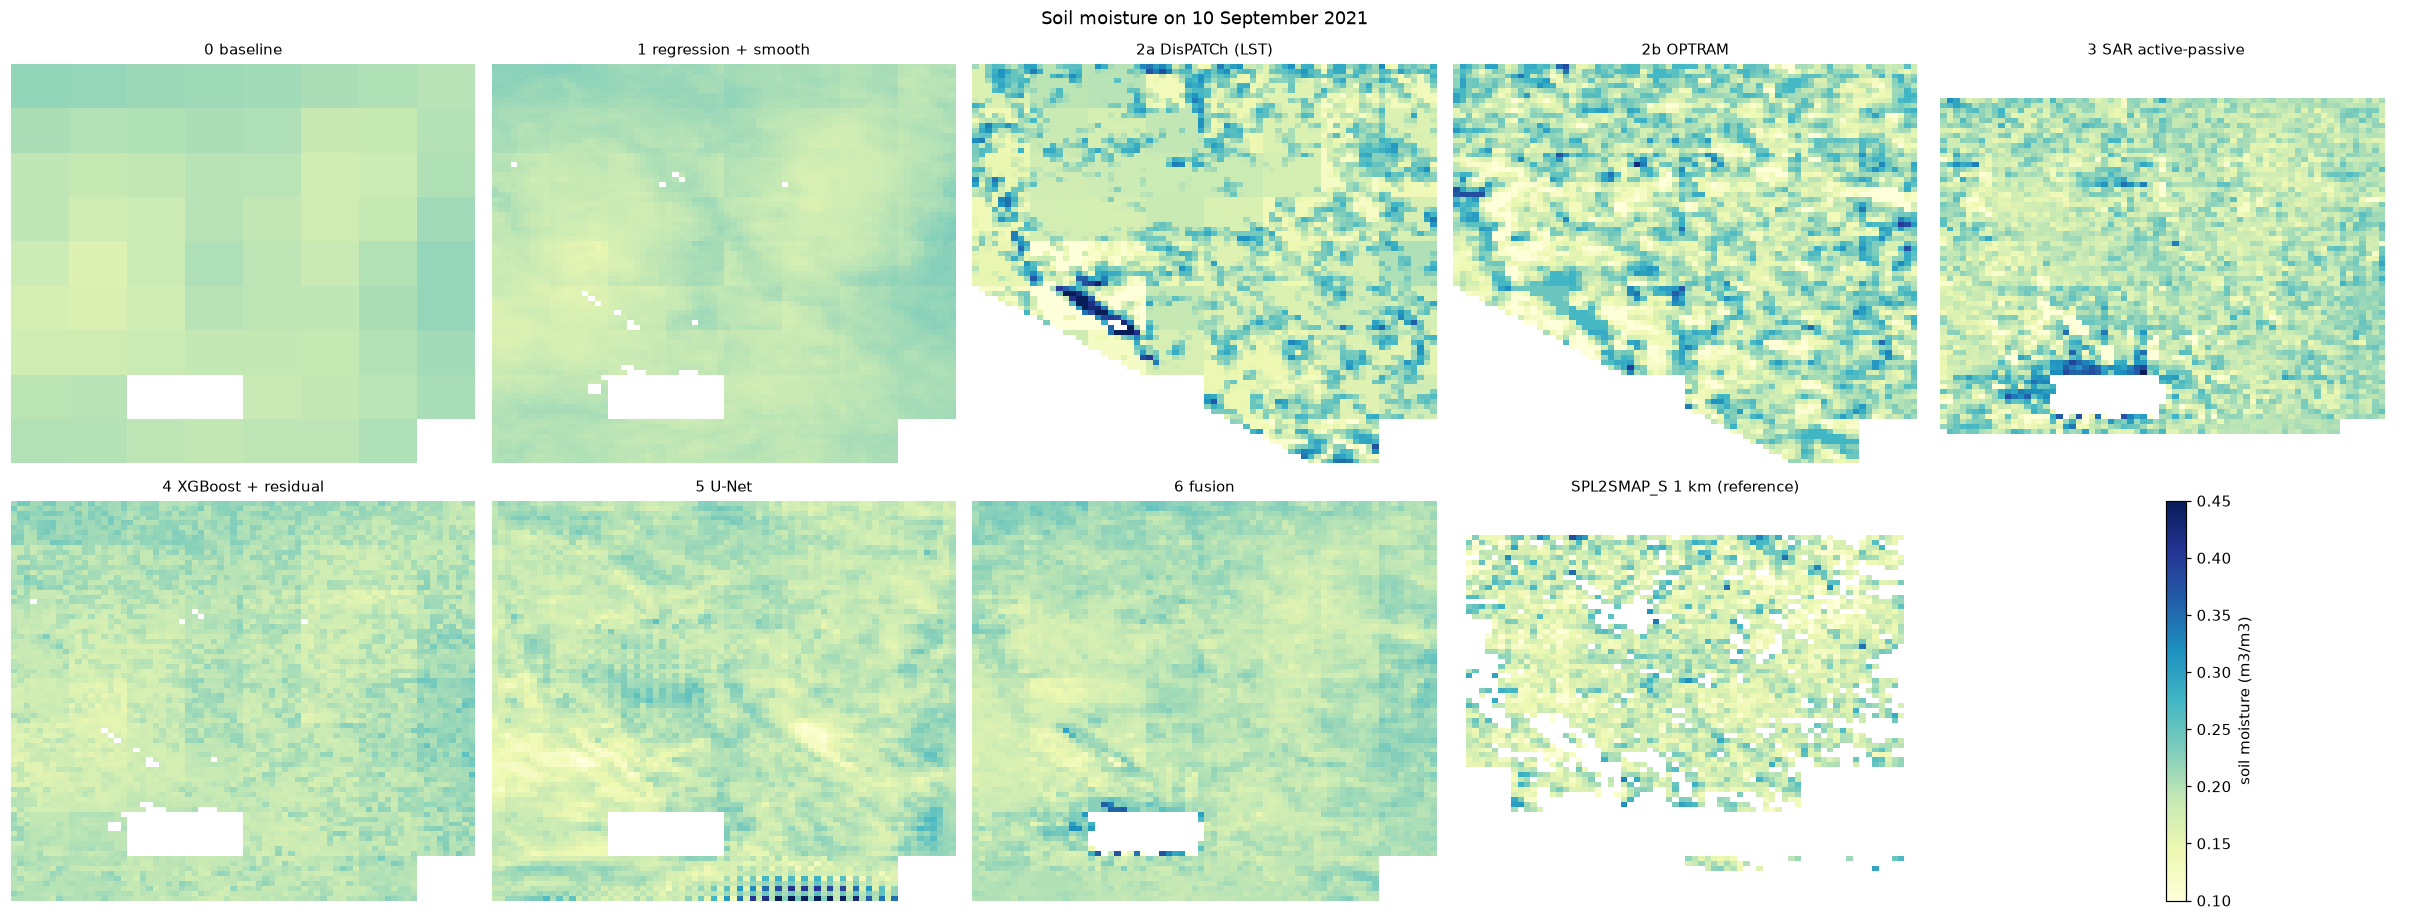

In [10]:
d21 = pd.DatetimeIndex([d for d in days if d.year == 2021])  # test year
cand = [d for d in d21 if float(spl.sel(time=d).notnull().mean()) > 0.3 and float(products["3 SAR active-passive"].sel(time=d).notnull().mean()) > 0.3]  # S1 days
show = max(cand, key=lambda d: float(products["2a DisPATCh (LST)"].sel(time=d).notnull().mean())) if cand else d21[100]  # best common day
names = list(products) + ["SPL2SMAP_S 1 km (reference)"]  # panels
maps = {**products, "SPL2SMAP_S 1 km (reference)": spl}  # all maps
fig, ax = plt.subplots(2, 5, figsize=(22, 8.5))  # nine maps and a colour bar
for a, k in zip(ax.ravel(), names):  # each map
    im = maps[k].sel(time=show).plot(ax=a, cmap="YlGnBu", vmin=0.1, vmax=0.45, add_colorbar=False); a.set_title(k, fontsize=10); a.axis("off")  # map
ax.ravel()[-1].axis("off"); fig.colorbar(im, ax=ax.ravel()[-1], fraction=0.5, label="soil moisture (m3/m3)")  # shared scale
plt.suptitle(f"Soil moisture on {show:%d %B %Y}"); plt.tight_layout(); plt.show()  # draw

The maps show how differently the methods distribute the same 9 km values. Regression and smoothing give
a gentle, plausible surface; XGBoost adds faint texture; DisPATCh and OPTRAM produce strong field-scale
contrasts with fixed blocks where clouds left a 9 km cell unchanged; the SAR method adds speckle-like
detail on the Sentinel-1 swath; the U-Net reproduces the texture of its SPL2SMAP_S training targets.

## The comparison

,availability,n vs SPL,within-cell R,ubRMSD vs SPL,gain vs baseline,mass error,station R (mean),station ubRMSD (mean),baseline station ubRMSD,seconds
method,,,,,,,,,,
0 baseline,0.582,42411,NaN,0.054,0.000,0.000,0.467,0.068,0.068,0.000
1 regression + smooth,0.579,42411,-0.001,0.055,-0.008,0.000,0.478,0.067,0.068,6.404
2a DisPATCh (LST),0.184,19359,0.003,0.079,-0.279,0.000,0.243,0.079,0.072,7.391
2b OPTRAM,0.492,39429,-0.109,0.070,-0.302,0.000,0.358,0.082,0.068,12.571
3 SAR active-passive,0.056,6523,0.112,0.044,-0.209,0.005,0.297,0.075,0.069,7.078
4 XGBoost + residual,0.579,42411,0.015,0.055,-0.025,0.000,0.455,0.069,0.068,3.769
5 U-Net,0.581,42343,0.172,0.056,-0.029,0.016,0.419,0.071,0.068,9.568
6 fusion,0.581,42411,-0.054,0.056,-0.037,0.000,0.467,0.068,0.068,0.274


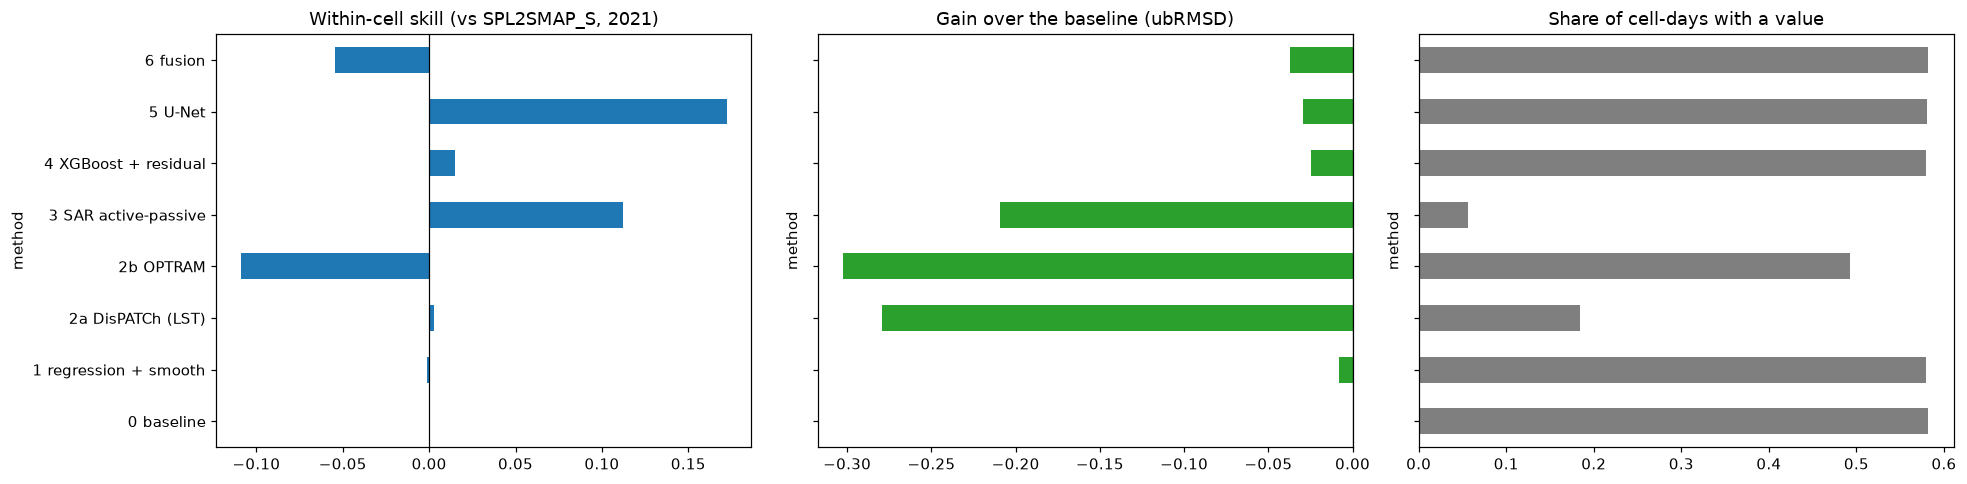

In [11]:
t6933 = Transformer.from_crs(4326, 6933, always_xy=True)  # station positions on the EASE grid
ins = {"USCRN Des Moines 17 E": sd.uscrn().sm_5.resample("1D").mean(), "SCAN Ames": sd.scan().sm_5}  # in situ 5 cm
test = d21  # 2021: no method saw it in training against SPL2SMAP_S
ref = spl.sel(time=test)  # reference maps
b = base.sel(time=test)  # baseline on the same days
rows = []  # one row per method
for k, p in products.items():  # each method
    pt = p.sel(time=test)  # test year
    ok = np.isfinite(pt.values) & np.isfinite(ref.values) & np.isfinite(b.values)  # cell-days with method, reference and baseline
    added, true_added = (pt - b).values[ok], (ref - b).values[ok]  # patterns
    within = np.corrcoef(added, true_added)[0, 1] if ok.sum() > 50 and np.std(added) > 1e-6 else np.nan  # within-cell skill
    ub_m = np.std(pt.values[ok] - ref.values[ok]); ub_b = np.std(b.values[ok] - ref.values[ok])  # ubRMSD of method and baseline
    blk = sm.block_mean(p.rio.write_crs("EPSG:6933"), F)  # 9 km view of the 1 km map
    mass = float(np.nanmean(np.abs(blk.values - coarse.values))) if blk.shape == coarse.shape else np.nan  # mass conservation error
    st_r = []  # station results
    for st, s in sd.STATIONS.iterrows():  # each station
        x, y = t6933.transform(s.lon, s.lat)  # position
        ser = p.sel(x=x, y=y, method="nearest").sel(time=test).to_series()  # method at the station cell
        bse = b.sel(x=x, y=y, method="nearest").to_series()  # baseline at the station
        both = pd.concat([ins[st].reindex(ser.index), ser, bse], axis=1).dropna()  # same days
        if len(both) > 10:  # enough days
            r_m = both.iloc[:, 0].corr(both.iloc[:, 1]); r_b = both.iloc[:, 0].corr(both.iloc[:, 2])  # correlations
            st_r.append((r_m, r_b, np.std(both.iloc[:, 1] - both.iloc[:, 0]), np.std(both.iloc[:, 2] - both.iloc[:, 0]), len(both)))  # values
    rows.append({"method": k, "availability": float(p.sel(time=test).notnull().mean()), "n vs SPL": int(ok.sum()),
                 "within-cell R": within, "ubRMSD vs SPL": ub_m, "gain vs baseline": 1 - ub_m / ub_b if ub_b > 0 else np.nan,
                 "mass error": mass,
                 "station R (mean)": np.mean([v[0] for v in st_r]) if st_r else np.nan,
                 "station ubRMSD (mean)": np.mean([v[2] for v in st_r]) if st_r else np.nan,
                 "baseline station ubRMSD": np.mean([v[3] for v in st_r]) if st_r else np.nan,
                 "seconds": timing.get(k, 0.0)})  # row
comp = pd.DataFrame(rows).set_index("method")  # table
display(comp.round(3))  # the comparison
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))  # three views
comp["within-cell R"].plot.barh(ax=ax[0], color="tab:blue"); ax[0].axvline(0, color="k", lw=0.8); ax[0].set_title("Within-cell skill (vs SPL2SMAP_S, 2021)")  # skill
comp["gain vs baseline"].plot.barh(ax=ax[1], color="tab:green"); ax[1].axvline(0, color="k", lw=0.8); ax[1].set_title("Gain over the baseline (ubRMSD)")  # gain
comp["availability"].plot.barh(ax=ax[2], color="tab:gray"); ax[2].set_title("Share of cell-days with a value")  # availability
for a in ax[1:]: a.set_yticklabels([])  # labels once
plt.tight_layout(); plt.show()  # draw
comp.to_csv(OUT / "downscaling_comparison_2021.csv")  # saved

The comparison is sobering, and typical of honest downscaling tests.

- **No method beats the baseline against SPL2SMAP_S in 2021.** Regression with smoothing (-0.8 %) and
  XGBoost (-2.5 %) come closest; the thermal and optical methods are 28 to 30 % worse, because their
  strong contrasts are not matched by the reference.
- **Within-cell skill is small everywhere.** The U-Net (0.17) and the SAR method (0.11) agree best with the
  reference's sub-cell pattern, but both share information with it: the U-Net was trained on SPL2SMAP_S
  and the SAR method uses the same Sentinel-1 backscatter that SPL2SMAP_S uses. The methods that use only
  independent information (texture, terrain, LST, OPTRAM) show no correlation with it.
- **At the stations** regression with smoothing is the only method slightly better than the baseline
  (R 0.48 against 0.47); fusion matches the baseline; the others are worse.
- **Mass conservation** holds for every method except the U-Net (0.016 m3 m-3), which learns its own level,
  and the SAR method, whose values are clipped to a physical range.
- **Availability** separates the methods most: regression, XGBoost, U-Net and fusion give a value
  wherever SMAP has one, OPTRAM on half of the days, DisPATCh on 18 % and the SAR method on 6 %.

Three reasons stand out. Central Iowa is flat and almost entirely corn and soybean, so the true variation
of soil moisture inside a 9 km cell is small compared with retrieval noise. The 1 km reference is itself
a downscaled product with errors of several hundredths of m3 m-3, so "truth" at 1 km is uncertain. And
two stations cannot judge 1 km patterns. A landscape with stronger contrasts (irrigation, soils, terrain)
and a dense field network such as SMAPVEX16 would test the methods more sharply.

## Summary and exercises

- On a grid nested in the coarse product, block means and copies are exact, which makes mass
  conservation and the baseline comparison unambiguous.
- Six method families were run on identical inputs over central Iowa (April to October 2019 to 2021)
  and judged on 2021, a year none of them was tuned or trained on against the reference.
- None beat the baseline of copying the 9 km value against SPL2SMAP_S; regression with a smooth,
  mass-preserving interpolation came closest and was the only method slightly better at the stations.
- Methods with some within-cell agreement (U-Net 0.17, SAR 0.11) share information with the reference;
  methods using only independent covariates showed none.
- Daily, complete products come from regression, machine learning, U-Net and fusion; DisPATCh is limited to
  clear days (18 %) and the SAR method to Sentinel-1 days (6 %).
- A downscaled map is a hypothesis about sub-cell variability: test it against the baseline and against a
  reference that does not share its inputs before using it.

**Exercises**

1. Run method 4 with `residual=False`. How much do the mass conservation error and the station metrics change?
2. Fit the DisPATCh edges over a whole month instead of each day. Does the number of usable days or the
   within-cell skill change?
3. Add Sentinel-1 VV aggregated to 1 km as a covariate of the XGBoost model on Sentinel-1 days only.
4. Train the U-Net with SPL2SMAP_S of 2019 only and test on 2020 and 2021. Is its skill stable from year to year?